In [ ]:
#spectral centroid


In [1]:
import torch
import librosa
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pathlib import Path

In [2]:
filepaths = list(Path("daria-recordings").glob("*.wav"))
print(len(filepaths))
print(filepaths[:3])

18
[PosixPath('daria-recordings/419118__mrthenoronha__guitar-riff-heavy.wav'), PosixPath('daria-recordings/16188__pitx__wah_two_electric_guitar.wav'), PosixPath('daria-recordings/chitara1.wav')]


In [3]:
def extract_centroid_windows(filepath, window_size=20, step=1):
    y, sr = librosa.load(str(filepath), sr=44100, mono=True)
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]

    windows = []
    for i in range(0, len(centroid) - window_size, step):
        window = centroid[i:i + window_size]
        windows.append(window)

    return np.array(windows)

In [4]:
all_centroid_windows = []
for fp in filepaths:
    windows = extract_centroid_windows(fp)
    all_centroid_windows.append(windows)

centroid_data = np.vstack(all_centroid_windows)
print(centroid_data.shape)

/var/folders/8t/cmgzfn3515b7_cvsv4pbv7g00000gn/T/ipykernel_35796/3566755988.py:2: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(str(filepath), sr=44100, mono=True)
/Users/daria/opt/anaconda3/envs/c4dm/lib/python3.12/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


(55947, 20)


In [5]:
from sklearn import preprocessing

centroid_scaler = preprocessing.MinMaxScaler()
centroid_scaled = centroid_scaler.fit_transform(centroid_data)

In [6]:
np.save("centroid-features.npy", centroid_scaled)

In [7]:
import numpy as np

data = np.load("centroid-features.npy")

np.random.seed(42)
np.random.shuffle(data)

split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print(train_data.shape, val_data.shape)

(50352, 20) (5595, 20)


In [8]:
from torch.utils.data import TensorDataset, DataLoader


centroid_tensor = torch.tensor(centroid_scaled, dtype=torch.float32)
centroid_dataset = TensorDataset(centroid_tensor)
centroid_dataloader = DataLoader(centroid_dataset, batch_size=64, shuffle=True)

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [11]:
class Centroid_Autoencoder(nn.Module):
    def __init__(self, input_dim=20, latent_dim=2, hidden_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        recon_x = self.decoder(z)
        return recon_x, z

In [12]:
model_centroid = Centroid_Autoencoder()
optimizer = torch.optim.Adam(model_centroid.parameters(), lr=1e-4)

for epoch in range(100):
    for batch in centroid_dataloader:
        x = batch[0]
        recon_x, z = model_centroid(x)
        loss = F.mse_loss(recon_x, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if (epoch+1) % 10 == 0:
        print(epoch+1, loss.item())



/Users/daria/opt/anaconda3/envs/c4dm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


10 0.00040837301639840007
20 0.00012785414583049715
30 0.00014845820260234177
40 0.0002854949270840734
50 0.00022757859551347792
60 8.688565867487341e-05
70 3.729639502125792e-05
80 0.00015165471995715052
90 0.00035569435567595065
100 0.0005036847433075309


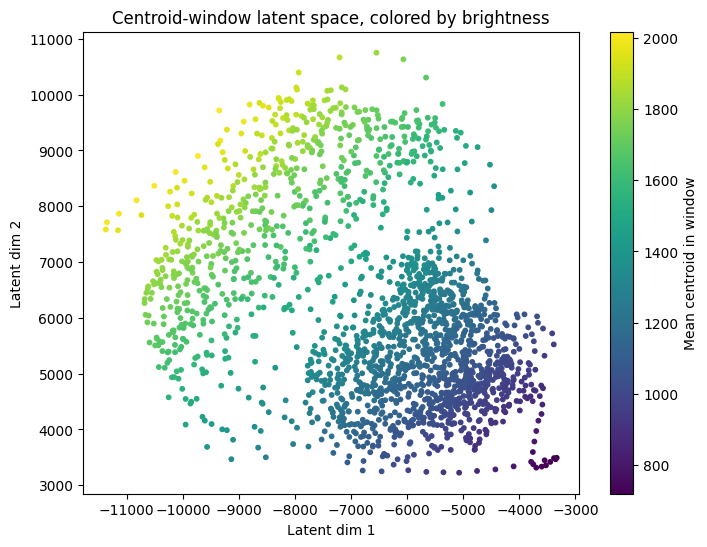

In [14]:
model_centroid.eval()

test_clip_windows = extract_centroid_windows("daria-recordings/chitara-pt-cod.wav")
test_tensor = torch.tensor(test_clip_windows, dtype=torch.float32)

with torch.no_grad():
    z = model_centroid.encoder(test_tensor)

z_np = z.numpy()
avg_centroid_per_window = test_clip_windows.mean(axis=1)

plt.figure(figsize=(8,6))
scatter = plt.scatter(z_np[:,0], z_np[:,1], c=avg_centroid_per_window, cmap='viridis', s=10)
plt.colorbar(scatter, label="Mean centroid in window")
plt.xlabel("Latent dim 1")
plt.ylabel("Latent dim 2")
plt.title("Centroid-window latent space, colored by brightness")
plt.show()

In [15]:
torch.save(model_centroid.state_dict(), "centroid_autoencoder.pt")